## Subquestion 2

This file contains the code for subquestion 2: *Has the severity of the traffic accidents in Amsterdam changed since the change in speed limit?* 

**Step 1 - Import libraries and load dataset** 



In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# Amsterdamse dataset inladen
df = pd.read_csv("ongevallen_gefilterd_amsterdam.csv")

# Eerste vijf rijen bekijken
display(df.head())

print("Number of accidents:", len(df))
print("Available columns:")
print(df.columns.tolist())


,VKL_NUMMER,DATUM_VKL,JAAR_VKL,MND_NUMMER,GME_ID,GME_NAAM,WVK_ID,JTE_ID,MAXSNELHD,AP3_CODE,ANTL_DOD,ANTL_GZH,ANTL_SEH,ANTL_SLA,period,speed_changed
0,20160000302,NaN,2016,NaN,363,Amsterdam,263360031.0,NaN,60.0,DOD,NaN,NaN,NaN,NaN,Before,NaN
1,20160000388,NaN,2016,NaN,363,Amsterdam,NaN,244369042.0,50.0,DOD,NaN,NaN,NaN,NaN,Before,NaN
2,20160000389,NaN,2016,NaN,363,Amsterdam,239373079.0,NaN,NaN,DOD,NaN,NaN,NaN,NaN,Before,NaN
3,20160000391,NaN,2016,NaN,363,Amsterdam,243375089.0,NaN,50.0,DOD,NaN,NaN,NaN,NaN,Before,NaN
4,20160000392,NaN,2016,NaN,363,Amsterdam,NaN,242376045.0,NaN,DOD,NaN,NaN,NaN,NaN,Before,NaN


Number of accidents: 63291
Available columns:
['VKL_NUMMER', 'DATUM_VKL', 'JAAR_VKL', 'MND_NUMMER', 'GME_ID', 'GME_NAAM', 'WVK_ID', 'JTE_ID', 'MAXSNELHD', 'AP3_CODE', 'ANTL_DOD', 'ANTL_GZH', 'ANTL_SEH', 'ANTL_SLA', 'period', 'speed_changed']


**Step 2 - Check and clean data**

We check if the AP3_CODE is read correctly. If the AP3_CODE is missing or spelled incorrectly, some accidents can be unwillingly excluded from the analysis. If an accident is stated two times, we don't want to actually count is two times. 
We also check if the years 2016 to 2025 are actually included in the output. Missing years are not supposed to be automatically interpreted as 0 accidents. 

In [2]:

# Jaar numeriek maken
df["JAAR_VKL"] = pd.to_numeric(
    df["JAAR_VKL"], errors="coerce"
)

# AP3_CODE uniform maken
df["AP3_CODE"] = (
    df["AP3_CODE"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Aantal geregistreerde ongevallen per jaar
print("Accidents per year:")
display(df["JAAR_VKL"].value_counts().sort_index())

# Verdeling van de ernstcategorieën
print("Severity categories:")
display(df["AP3_CODE"].value_counts(dropna=False))

# Controle op dubbele ongevallen
print("Duplicate accident IDs:")
print(df["VKL_NUMMER"].duplicated().sum())


Accidents per year:


JAAR_VKL
2016    6811
2017    6884
2018    7156
2019    7142
2020    5018
2021    5317
2022    5979
2023    6813
2024    6201
2025    5970
Name: count, dtype: int64

Severity categories:


AP3_CODE
UMS    52172
LET    10965
DOD      154
Name: count, dtype: int64[pyarrow]

Duplicate accident IDs:
0


**Step 3 - Creating investigation periods**

We create two investigation periods:
- trend_data: all years 2016-2025, including 2023.
- analysis: only the years before and after the intervention that we compare.

We use trend_data to see the complete development and we use analysis for the statistical comparison. That way, we don't delete the year 2023 from the data.  

In [3]:

# Selecteer geldige jaren en ernstcategorieën
trend_data = df[
    df["JAAR_VKL"].between(2016, 2025)
    & df["AP3_CODE"].isin(["DOD", "LET", "UMS"])
].copy()

# Maak de drie onderzoeksperioden
trend_data["period"] = "Before"

trend_data.loc[
    trend_data["JAAR_VKL"] == 2023,
    "period"
] = "Transition"

trend_data.loc[
    trend_data["JAAR_VKL"] >= 2024,
    "period"
] = "After"

# Dataset voor de before/after-analyse
analysis = trend_data[
    trend_data["period"].isin(["Before", "After"])
].copy()

print("Trend dataset:", len(trend_data))
print("Before/After dataset:", len(analysis))

display(
    pd.crosstab(
        trend_data["JAAR_VKL"],
        trend_data["period"]
    )
)


Trend dataset: 63291
Before/After dataset: 56478


period,After,Before,Transition
JAAR_VKL,,,
2016,0,6811,0
2017,0,6884,0
2018,0,7156,0
2019,0,7142,0
2020,0,5018,0
2021,0,5317,0
2022,0,5979,0
2023,0,0,6813
2024,6201,0,0


**Step 4 - Number of accidents per severity category per year**

With pd.crosstab(), we create a table that that counts how many occur in every category. This shows if the amount of accidents with injuries and fatalities changes over the years.

In [5]:

# Tel ongevallen per jaar en ernstcategorie
severity_yearly = pd.crosstab(
    trend_data["JAAR_VKL"],
    trend_data["AP3_CODE"]
)

# Zorg voor vaste kolomvolgorde
categories = ["DOD", "LET", "UMS"]

severity_yearly = severity_yearly.reindex(
    columns=categories,
    fill_value=0
)

# Totaal per jaar
severity_yearly["Total"] = severity_yearly.sum(axis=1)

display(severity_yearly)


AP3_CODE,DOD,LET,UMS,Total
JAAR_VKL,,,,
2016,11,1391,5409,6811
2017,13,1322,5549,6884
2018,17,1128,6011,7156
2019,15,988,6139,7142
2020,14,795,4209,5018
2021,15,798,4504,5317
2022,14,1058,4907,5979
2023,14,1122,5677,6813
2024,21,1171,5009,6201


**Step 5 - Graph of the yearly development**

There are 4 graphs created:
- Two seperate graphs for the injuries and fatalities per year
- A combined graph, with two different y-axes, with the injuries and fatalities per year
- A graph for both trends on the same scale

We create seperate graphs for the fatalities and injuries, because those numbers probably are substantially lower, and their y-axes are not on the same scale. Even when both y-axes start in the origin, the graphs are not one-on-one comparable for their height or slope. If the slope looks the same, it does not necessarily indicate the same percentual change.
The last graph sets the amount of accidents in 2016 to 100 for both categories. Next, the index value of the next year is calculated. Therefore, both lines are on the exact same relative scale and thus better comparable.  

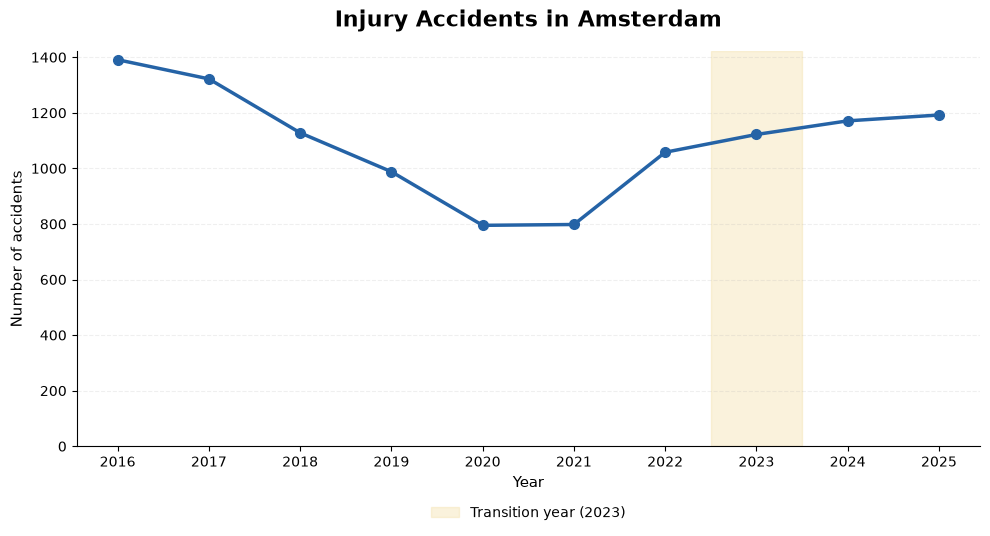

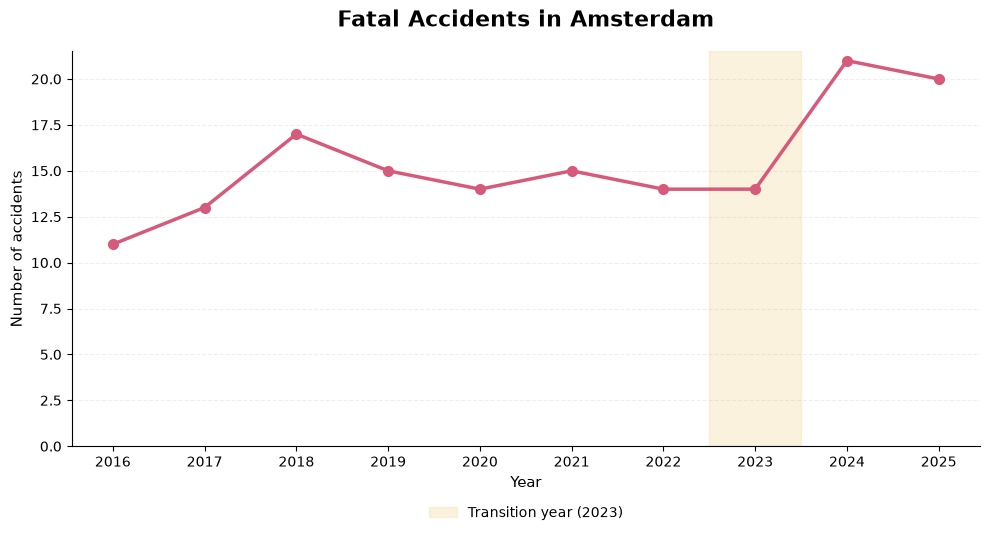

In [ ]:
#Twee losse grafieken voor de verschillende categorieën

# Definieer de categorieën
graphs = {
    "LET": {
        "title": "Injury Accidents in Amsterdam",
        "color": "#2563A6",
        "filename": "RQ2_injury_accidents.png"
    },
    "DOD": {
        "title": "Fatal Accidents in Amsterdam",
        "color": "#D65A7A",
        "filename": "RQ2_fatal_accidents.png"
    }
}

# Maak voor elke categorie een aparte grafiek
for category, settings in graphs.items():

    fig, ax = plt.subplots(figsize=(10, 5.5))

    ax.plot(
        severity_yearly.index,
        severity_yearly[category],
        color=settings["color"],
        marker="o",
        markersize=7,
        linewidth=2.5
    )

    # Markeer 2023
    ax.axvspan(
        2022.5, 2023.5,
        color="#F4DFA8",
        alpha=0.4,
        label="Transition year (2023)"
    )

    # Titel en labels
    ax.set_title(
        settings["title"],
        fontsize=16,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel("Year", fontsize=11)
    ax.set_ylabel("Number of accidents", fontsize=11)

    ax.set_xticks(range(2016, 2026))

    # Y-as begint op nul
    ax.set_ylim(bottom=0)

    # Zwarte assen
    ax.tick_params(axis="both", labelcolor="black")

    # Subtiele horizontale grid
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.2
    )

    # Randen verwijderen
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Legenda
    ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
    fontsize=10
    )
    plt.tight_layout()

    # Opslaan
    plt.savefig(
        settings["filename"],
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()




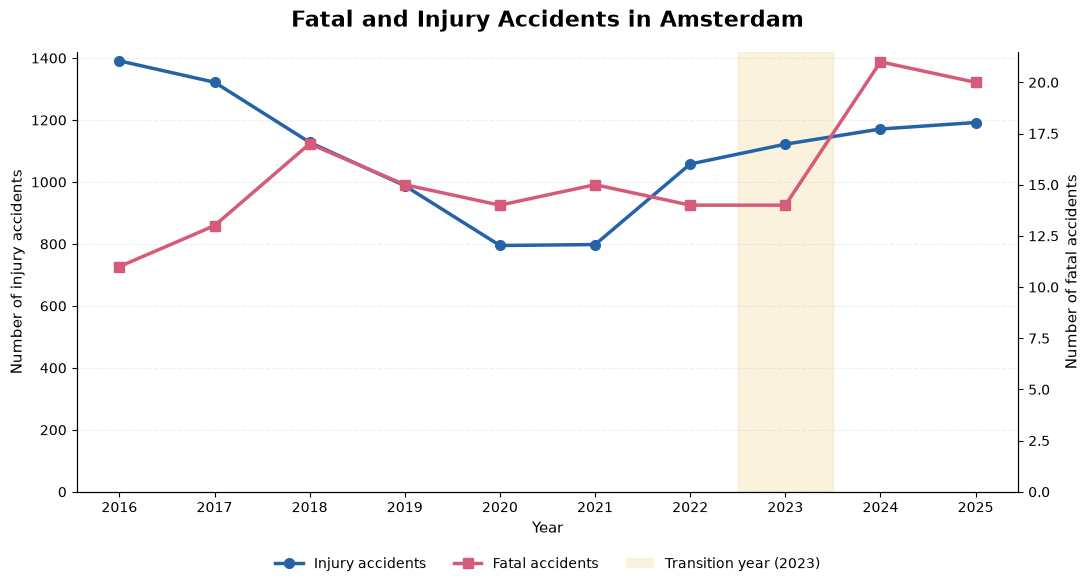

In [ ]:
#Gecombineerde grafiek met twee y-assen

# Kleuren
blue = "#2563A6"
pink = "#D65A7A"

# Grafiek aanmaken
fig, ax1 = plt.subplots(figsize=(11, 6))
ax2 = ax1.twinx()

# Letselongevallen
line1, = ax1.plot(
    severity_yearly.index,
    severity_yearly["LET"],
    color=blue,
    marker="o",
    markersize=7,
    linewidth=2.5,
    label="Injury accidents"
)

# Dodelijke ongevallen
line2, = ax2.plot(
    severity_yearly.index,
    severity_yearly["DOD"],
    color=pink,
    marker="s",
    markersize=7,
    linewidth=2.5,
    label="Fatal accidents"
)

# 2023 markeren
ax1.axvspan(
    2022.5, 2023.5,
    color="#F4DFA8",
    alpha=0.4
)

# Assen en labels
ax1.set_xlabel("Year", fontsize=11)
ax1.set_ylabel(
    "Number of injury accidents",
    fontsize=11,
    color="black"
)
ax2.set_ylabel(
    "Number of fatal accidents",
    fontsize=11,
    color="black"
)

ax1.tick_params(axis="both", labelcolor="black")
ax2.tick_params(axis="both", labelcolor="black")

ax1.set_xticks(range(2016, 2026))

# Beide schalen beginnen op nul
ax1.set_ylim(bottom=0)
ax2.set_ylim(bottom=0)

# Titel
ax1.set_title(
    "Fatal and Injury Accidents in Amsterdam",
    fontsize=16,
    fontweight="bold",
    pad=18
)

# Subtiele horizontale lijnen
ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)

# Randen verwijderen
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# Legenda

from matplotlib.patches import Patch

# Maak een legenda-item voor de overgangsperiode
transition_patch = Patch(
    facecolor="#F4DFA8",
    alpha=0.4,
    label="Transition year (2023)"
)

# Alle drie de items in één legenda
ax1.legend(
    handles=[line1, line2, transition_patch],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "RQ2_combined_absolute.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



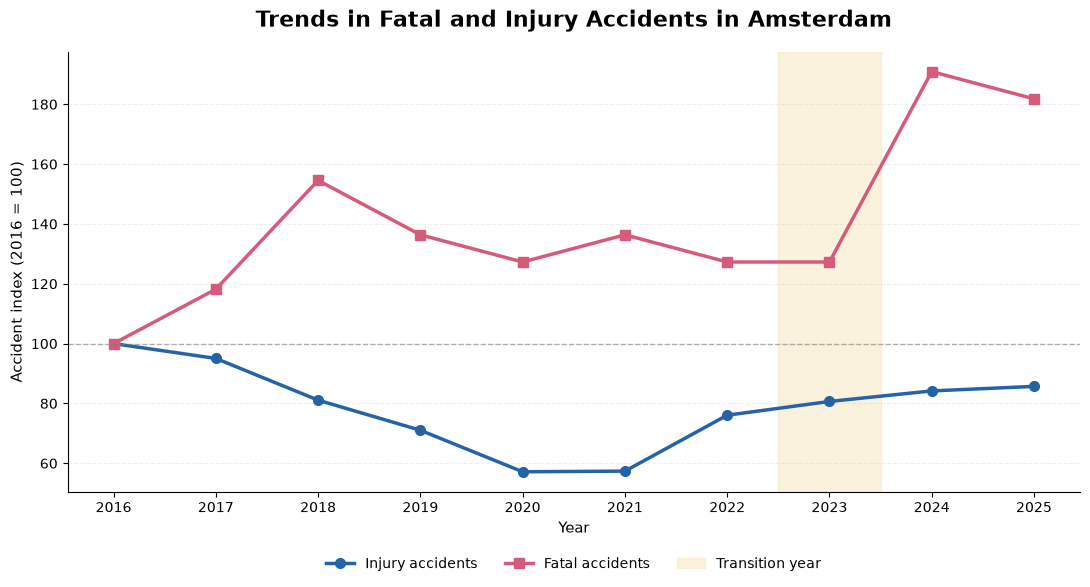

In [11]:
#Gecombineerde graifek met indexering ten opzichte van 2016

# Index berekenen ten opzichte van 2016
baseline = severity_yearly.loc[
    2016, ["LET", "DOD"]
]

# Controle: delen door nul voorkomen
if (baseline == 0).any():
    raise ValueError(
        "2016 has zero accidents in one category. "
        "Choose another baseline year."
    )

indexed = (
    severity_yearly[["LET", "DOD"]]
    .div(baseline)
    * 100
)

# Kleuren
blue = "#2563A6"
pink = "#D65A7A"

fig, ax = plt.subplots(figsize=(11, 6))

# Letselongevallen
ax.plot(
    indexed.index,
    indexed["LET"],
    color=blue,
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Injury accidents"
)

# Dodelijke ongevallen
ax.plot(
    indexed.index,
    indexed["DOD"],
    color=pink,
    marker="s",
    linewidth=2.5,
    markersize=7,
    label="Fatal accidents"
)

# Interventiejaar markeren
ax.axvspan(
    2022.5, 2023.5,
    color="#F4DFA8",
    alpha=0.4,
    label="Transition year"
)

# Referentielijn 100
ax.axhline(
    100,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

# Titel en assen
ax.set_title(
    "Trends in Fatal and Injury Accidents in Amsterdam",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Accident index (2016 = 100)", fontsize=11)

ax.set_xticks(range(2016, 2026))

# Zwarte tekst
ax.tick_params(axis="both", labelcolor="black")

# Grid
ax.grid(axis="y", alpha=0.2, linestyle="--")

# Randen verwijderen
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legenda
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    "RQ2_indexed_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Step 6 - Yearly average Before vs After**

We now compare the yearly average number of accidents per year in 2016-2022 with the average in 2024-2025. We then interpret this by calculating the percentual change.

In [15]:

# Gemiddelde per jaar in de voorperiode
before_avg = severity_yearly.loc[
    2016:2022, categories
].mean()

# Gemiddelde per jaar in de naperiode
after_avg = severity_yearly.loc[
    2024:2025, categories
].mean()

# Procentuele verandering
change_pct = (
    (after_avg - before_avg)
    / before_avg.replace(0, np.nan)
) * 100

# Maak vergelijkingstabel
comparison = pd.DataFrame({
    "Before (annual average)": before_avg,
    "After (annual average)": after_avg,
    "Change (%)": change_pct
})

display(comparison.round(2))


,Before (annual average),After (annual average),Change (%)
AP3_CODE,,,
DOD,14.14,20.5,44.95
LET,1068.57,1181.5,10.57
UMS,5246.86,4883.5,-6.93


**Step 7 - Relative severity distribution** 

We investigate which percentage of the registered accidents belongs to the categories DOD, LET and UMS.

In [16]:

# Aantallen per periode en ernstcategorie
severity_counts = pd.crosstab(
    analysis["period"],
    analysis["AP3_CODE"]
).reindex(
    index=["Before", "After"],
    columns=["DOD", "LET", "UMS"],
    fill_value=0
)

# Bereken percentage per periode
severity_percentages = (
    severity_counts.div(
        severity_counts.sum(axis=1),
        axis=0
    ) * 100
)

print("Absolute numbers:")
display(severity_counts)

print("Severity distribution (%):")
display(severity_percentages.round(2))


Absolute numbers:


AP3_CODE,DOD,LET,UMS
period,,,
Before,99,7480,36728
After,41,2363,9767


Severity distribution (%):


AP3_CODE,DOD,LET,UMS
period,,,
Before,0.22,16.88,82.89
After,0.34,19.42,80.25


**Step 8 - Stacked bar chart**

With this bar chart, we can compare the severity distribution clearly. There are two bars per category: one bar for the period before the intervention, one bar for the period after. Together, the bars in the categories add to 100% (for each period of time seperately). The percentage of the fatal accidents was so small, that we added graph with only the percentages of the fatal accidents with different axes.  

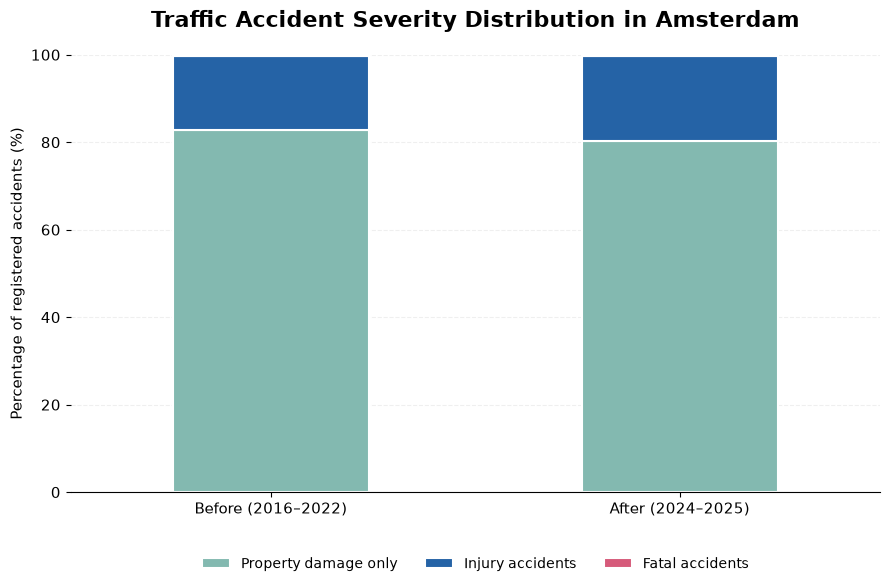

In [18]:
#Stacked bar chart maken

# Kleuren passend bij de andere grafieken
colors = {
    "DOD": "#D65A7A",  # Roze - fatal
    "LET": "#2563A6",  # Blauw - injury
    "UMS": "#83B9B0"   # Zacht turquoise - property damage
}

# Grafiek aanmaken
fig, ax = plt.subplots(figsize=(9, 6))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Gestapelde staafgrafiek
severity_percentages[["UMS", "LET", "DOD"]].plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[
        colors["UMS"],
        colors["LET"],
        colors["DOD"]
    ],
    width=0.48,
    edgecolor="white",
    linewidth=1.5
)

# Titel en assen
ax.set_title(
    "Traffic Accident Severity Distribution in Amsterdam",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel(
    "Percentage of registered accidents (%)",
    fontsize=11,
    color="black"
)

# Y-as van 0 tot 100
ax.set_ylim(0, 100)

# Zwarte getallen en tekst
ax.tick_params(
    axis="both",
    labelcolor="black",
    labelsize=11
)

ax.set_xticklabels(
    ["Before (2016–2022)", "After (2024–2025)"],
    rotation=0
)

# Subtiele horizontale rasterlijnen
ax.set_axisbelow(True)
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)

# Randen verwijderen
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Legenda onder de grafiek
ax.legend(
    ["Property damage only", "Injury accidents", "Fatal accidents"],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
    fontsize=10
)

plt.tight_layout()

# Opslaan voor het verslag
plt.savefig(
    "RQ2_severity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



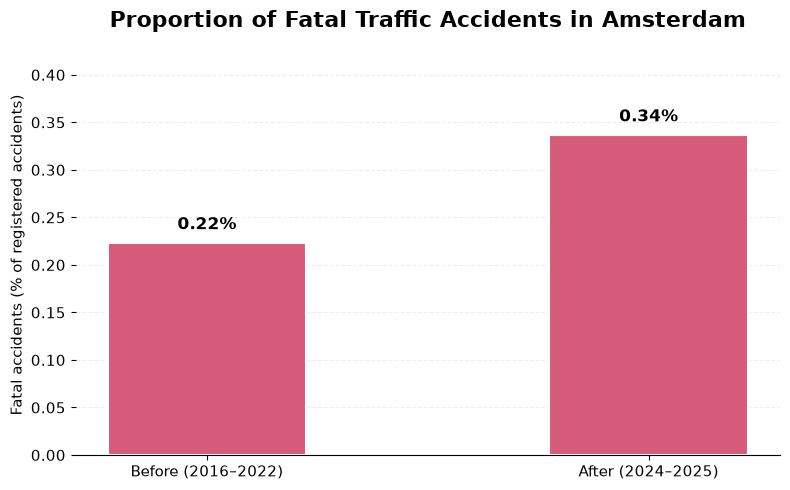

In [19]:


# Percentage dodelijke ongevallen
fatal_percentages = severity_percentages["DOD"]

# Kleuren
pink = "#D65A7A"

# Grafiek maken
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Before (2016–2022)", "After (2024–2025)"],
    fatal_percentages.values,
    color=pink,
    width=0.45,
    edgecolor="white",
    linewidth=1.5
)

# Exacte percentages boven de staven
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color="black"
    )

# Titel en labels
ax.set_title(
    "Proportion of Fatal Traffic Accidents in Amsterdam",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_ylabel(
    "Fatal accidents (% of registered accidents)",
    fontsize=11,
    color="black"
)

ax.set_xlabel("")

# Ingezoomde y-as, begint bij nul
ax.set_ylim(
    0,
    fatal_percentages.max() * 1.25
)

# Zwarte tekst
ax.tick_params(
    axis="both",
    labelcolor="black",
    labelsize=11
)

# Subtiele grid
ax.set_axisbelow(True)
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)

# Randen verwijderen
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()

# Opslaan
plt.savefig(
    "RQ2_fatal_percentage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Step 9A - Chi-square test**

Now, we will statistically test if the distribution of the three severity categories has changed. The hypotheses are:
    H0: The severity distribution is equal in both periods.
    H1: The severity distribution differs in both periods. 

What does the p-value mean?
- p < 0.05: there is statistic evidence for a difference in the severity distribution.
- p > 0.05: there is insufficient evidence to determine a difference.

In [21]:

# Controleer of iedere categorie waarnemingen bevat

test_counts = severity_counts.loc[
    :,
    severity_counts.sum(axis=0) > 0
]

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    test_counts
)

print("Chi-square statistic:", round(chi2, 3))
print("Degrees of freedom:", dof)
print("P-value:", round(p_value, 5))
print("Minimum expected frequency:", expected.min())

# Interpretatie
if (expected < 5).any():
    print(
        "Warning: low expected frequencies. "
        "Consider an exact or simulation-based test."
    )

if p_value < 0.05:
    print(
        "Statistically significant difference "
        "in accident severity distribution."
    )
else:
    print(
        "No statistically significant difference "
        "in accident severity distribution detected."
    )

# P-waarde met meer precisie weergeven
print(f"P-value: {p_value:.10e}")

Chi-square statistic: 48.223
Degrees of freedom: 2
P-value: 0.0
Minimum expected frequency: 30.16997769042813
Statistically significant difference in accident severity distribution.
P-value: 3.3771703548e-11


**Step 9B - Effect size (Cramér's V)**

The Chi-square test determines *if* a relationship exists, while Cramér's V determines *how strong* that relationship is. Cramér's V lies between 0 and 1. The closer to 0, the weaker the relation. 

In [22]:

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    severity_counts
)

# Totaal aantal ongevallen
n = severity_counts.to_numpy().sum()

# Aantal rijen en kolommen
rows, cols = severity_counts.shape

# Bereken Cramér's V
cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, cols - 1))
)

# Resultaten weergeven
print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.3e}")
print(f"Cramér's V: {cramers_v:.4f}")

# Interpretatie
if cramers_v < 0.1:
    print("Very small association")
elif cramers_v < 0.3:
    print("Small association")
elif cramers_v < 0.5:
    print("Moderate association")
else:
    print("Large association")


Chi-square statistic: 48.223
P-value: 3.377e-11
Cramér's V: 0.0292
Very small association


**Step 10 - Extra analysis: severe vs non-severe accidents**

In this additional analysis, make a distinction between accidents with injuries or casualties. This is useful, because seperately, fatal accidents are relatively rare. We now combine the two categories LET and DOD into one.  

In [23]:

# Nieuwe ernstcategorie
analysis["severity_binary"] = np.where(
    analysis["AP3_CODE"].isin(["DOD", "LET"]),
    "Fatal/Injury",
    "Property damage only"
)

# Kruistabel
binary_counts = pd.crosstab(
    analysis["period"],
    analysis["severity_binary"]
)

# Percentages
binary_percentages = (
    binary_counts.div(
        binary_counts.sum(axis=1),
        axis=0
    ) * 100
)

display(binary_percentages.round(2))

# Statistische toets
chi2_binary, p_binary, dof_binary, expected_binary = (
    chi2_contingency(binary_counts)
)

print("P-value:", round(p_binary, 5))


severity_binary,Fatal/Injury,Property damage only
period,,
After,19.75,80.25
Before,17.11,82.89


P-value: 0.0


**Step 11 - Sensitivity analysis**

A sensitivity analysis determines whether the results change when you adjust ceratain assumptions. In our analysis, we now compare:
- Before: 2016 - 2022
- After: 2024 - 2025

However, 2020 and 2021 were COVID years. There was a lockdown in Amsterdam, and therefore there was significantly fewer traffic. This may have an impact on our and results. Due to this possible disruption in the data, we perform a second analaysis, where we leave out 2020 and 2021. We then compare the results.

In [25]:

#Sensitivity analysis

# Coronajaren uitsluiten
sensitivity_data = analysis[
    ~analysis["JAAR_VKL"].isin([2020, 2021])
].copy()

# Nieuwe ernstverdeling berekenen
sensitivity_counts = pd.crosstab(
    sensitivity_data["period"],
    sensitivity_data["AP3_CODE"]
).reindex(
    index=["Before", "After"],
    columns=["DOD", "LET", "UMS"],
    fill_value=0
)

# Percentages berekenen
sensitivity_percentages = (
    sensitivity_counts.div(
        sensitivity_counts.sum(axis=1),
        axis=0
    ) * 100
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    sensitivity_counts
)

# Cramér's V
n = sensitivity_counts.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        sensitivity_counts.shape[0] - 1,
        sensitivity_counts.shape[1] - 1
    ))
)

print("Severity distribution excluding COVID years:")
display(sensitivity_percentages.round(2))

print(f"P-value: {p_value:.3e}")
print(f"Cramér's V: {cramers_v:.4f}")


Severity distribution excluding COVID years:


AP3_CODE,DOD,LET,UMS
period,,,
Before,0.21,17.33,82.46
After,0.34,19.42,80.25


P-value: 5.155e-08
Cramér's V: 0.0270
